[1/46] Paenibacillus litoralis: 8,741,851 bp, GC 52.8%, 7,246 proteins
[2/46] Paenibacillus bovis: 5,354,277 bp, GC 47.3%, 4,551 proteins
[3/46] Paenibacillus chitinolyticus: 6,509,090 bp, GC 52.4%, 5,841 proteins
[4/46] Paenibacillus graminis: 7,166,464 bp, GC 50.6%, 6,209 proteins
[5/46] Paenibacillus durus: 6,038,347 bp, GC 50.8%, 5,363 proteins
[6/46] Paenibacillus sophorae: 5,867,720 bp, GC 50.2%, 5,628 proteins
[7/46] Paenibacillus kribbensis: 5,778,702 bp, GC 46.8%, 5,109 proteins
[8/46] Paenibacillus odorifer: 6,812,473 bp, GC 44.2%, 5,956 proteins
[9/46] Paenibacillus chondroitinus: 8,010,791 bp, GC 46.3%, 7,221 proteins
[10/46] Paenibacillus riograndensis: 7,919,576 bp, GC 51.0%, 6,700 proteins
[11/46] Paenibacillus polymyxa: 5,921,998 bp, GC 45.1%, 5,373 proteins
[12/46] Paenibacillus kyungheensis: 5,260,882 bp, GC 39.3%, 4,543 proteins
[13/46] Paenibacillus donghaensis: 8,542,333 bp, GC 49.7%, 7,724 proteins
[14/46] Paenibacillus borealis: 8,156,808 bp, GC 51.4%, 6,964 prot

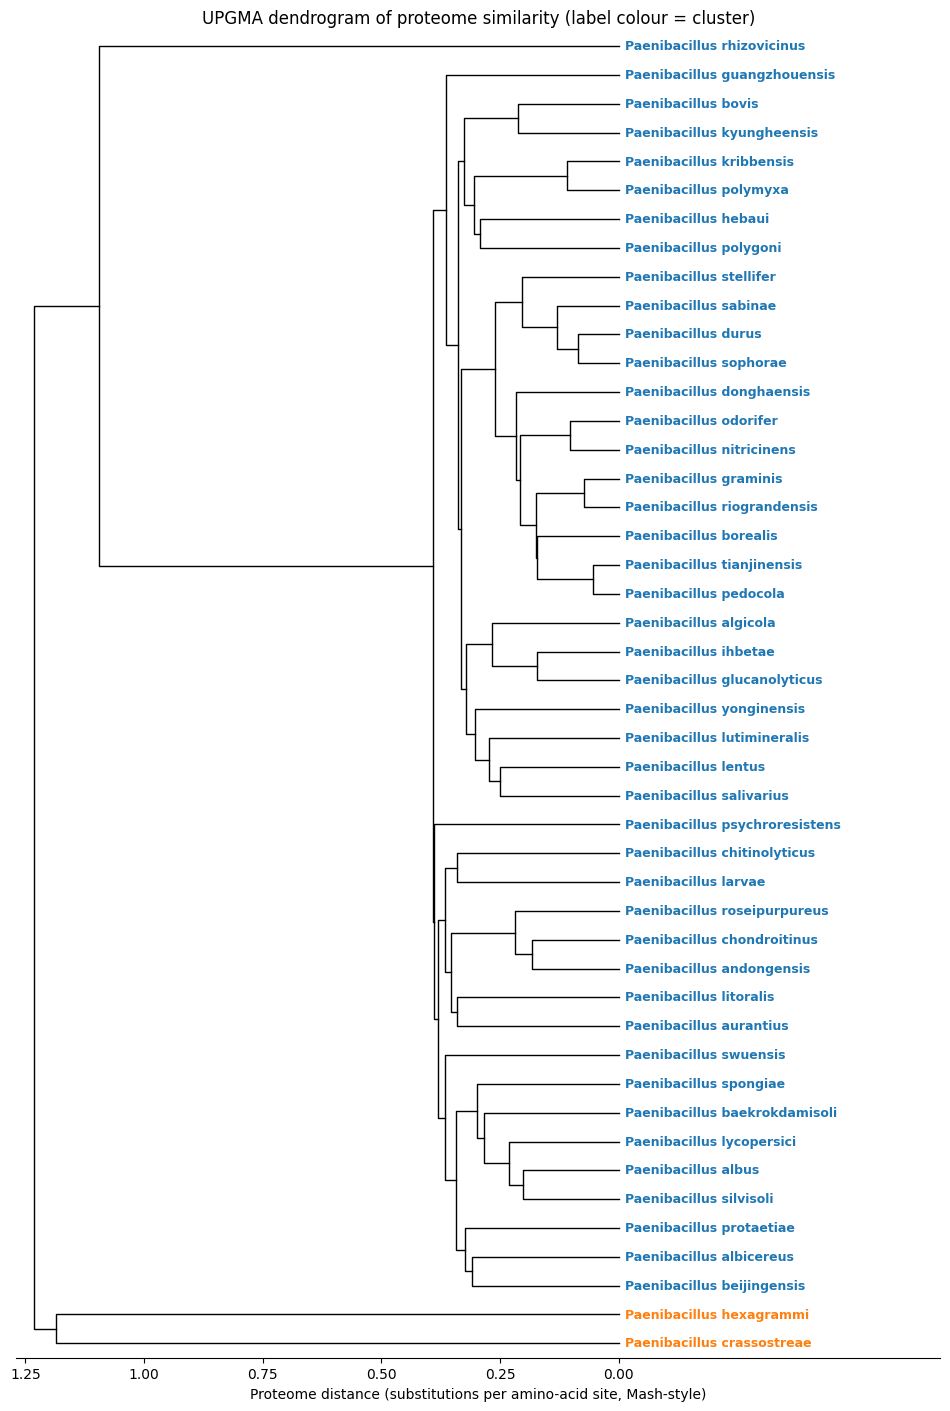

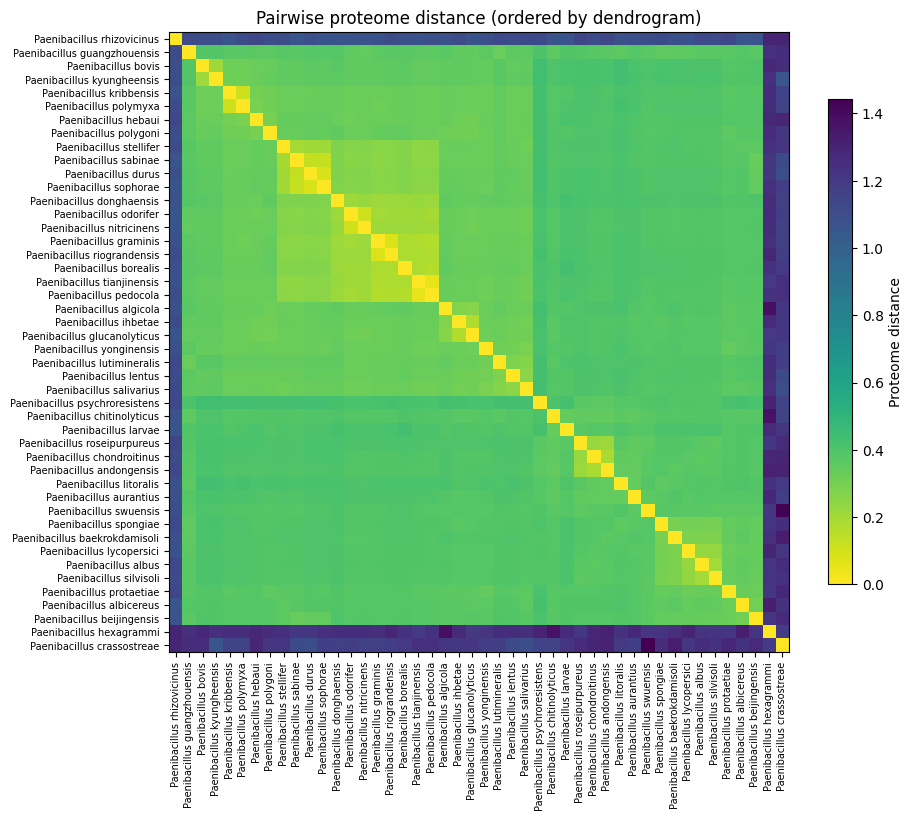

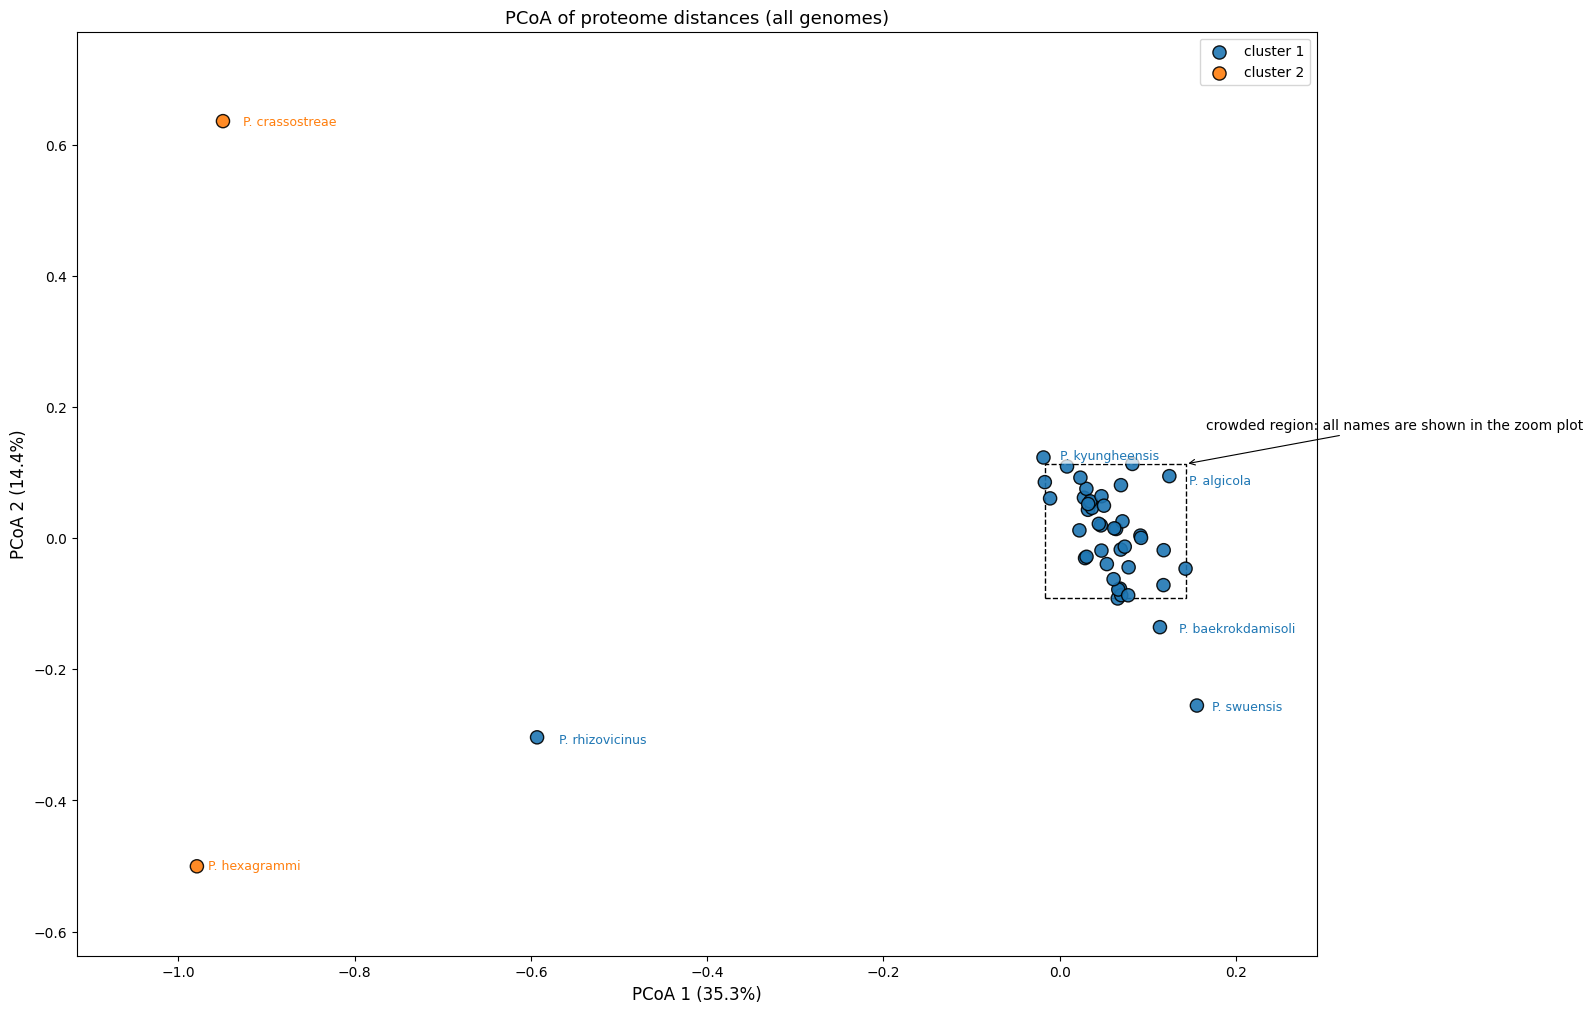

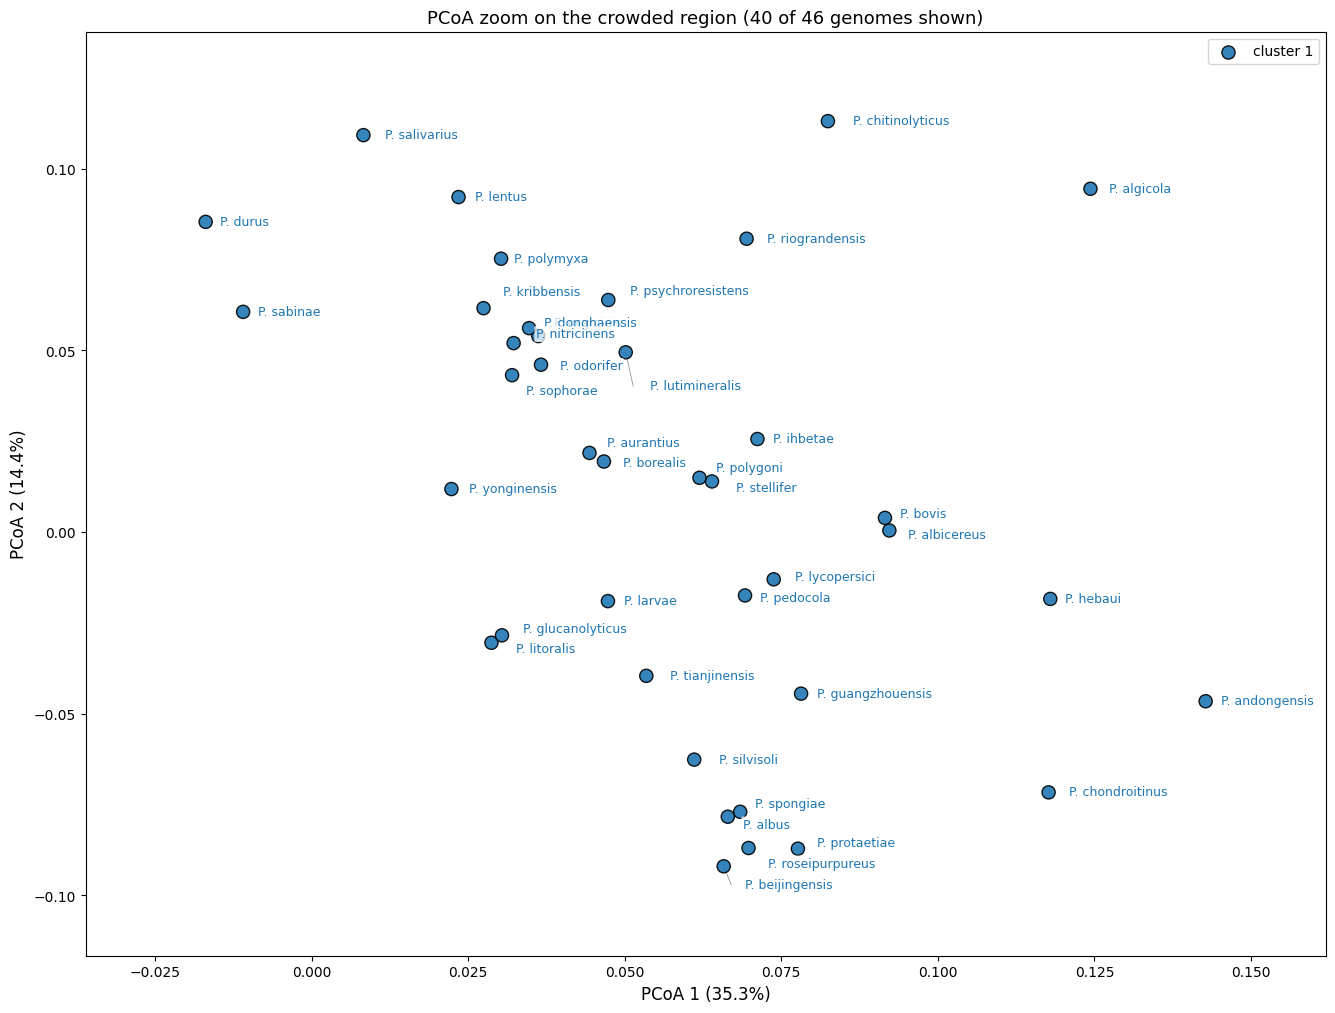


Done. Results are in 'results'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
"""
Clustering and tree analysis of bacterial genomes (Google Colab, pure Python)
============================================================================
Compares whole genomes WITHOUT alignment, using two complementary measures:

  A. DNA similarity (Mash-style, 21-mers)   -> ANI-like values.
     Reliable for close relatives (about 80-100 % ANI): spots same-species pairs.
     Genomes from different species of a genus usually share too few 21-mers, so this
     is NOT used to build the genus-wide tree.

  B. Proteome similarity (Mash-style, amino-acid 7-mers from predicted proteins)
     -> works across a whole genus. Used for the tree, clusters and PCoA.

Outputs: distance matrices, Newick trees (neighbour-joining and UPGMA), cluster
assignments, dendrogram, heatmap, PCoA plot, optional overlay of the chitin score,
summary.txt, all zipped into results.zip.

How to use in Colab
    1. New notebook -> paste this whole script into ONE cell
    2. Add the accessions to GENOMES (same list as the chitin screen)
    3. (Optional) upload chitin_feature_table.csv from the chitin screen and keep CHITIN_TABLE
       as is, to colour the tree by chitin score
    4. Run. results.zip downloads at the end.
Packages: pyrodigal is installed automatically (numpy, pandas, scipy, matplotlib are in Colab).
"""
import gzip
import re
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, to_tree
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------
# SETTINGS
# ----------------------------------------------------------------------
GENOMES = {
        "Paenibacillus litoralis": "NZ_CP176395.1",
    "Paenibacillus bovis": "NZ_CP013023.1",
    "Paenibacillus chitinolyticus": "NZ_CP026520.1",
    "Paenibacillus graminis": "NZ_CP009287.1",
    "Paenibacillus durus": "NZ_CP009288.1",
    "Paenibacillus sophorae": "NZ_CP076607.1",
    "Paenibacillus kribbensis": "NZ_CP020028.1",
    "Paenibacillus odorifer": "NZ_CP009428.1",
    "Paenibacillus chondroitinus": "NZ_CM137256.1",
    "Paenibacillus riograndensis": "NZ_LN831776.1",
    "Paenibacillus polymyxa": "NZ_CP024795.1",
    "Paenibacillus kyungheensis": "NZ_CP117416.1",
    "Paenibacillus donghaensis": "NZ_CP021780.1",
    "Paenibacillus borealis": "NZ_CP009285.1",
    "Paenibacillus psychroresistens": "NZ_CP034235.1",
    "Paenibacillus andongensis": "NZ_CP104467.1",
    "Paenibacillus spongiae": "NZ_CP091430.1",
    "Paenibacillus baekrokdamisoli": "NZ_AP019308.1",
    "Paenibacillus hebaui": "NZ_CP196836.1",
    "Paenibacillus rhizovicinus": "NZ_CP048288.1",
    "Paenibacillus guangzhouensis": "NZ_CP045293.1",
    "Paenibacillus yonginensis": "NZ_CP014167.1",
    "Paenibacillus swuensis": "NZ_CP011388.1",
    "Paenibacillus albicereus": "NZ_CP051428.1",
    "Paenibacillus sabinae": "NZ_CP004078.1	",
    "Paenibacillus lentus": "NZ_CP034248.1",
    "Paenibacillus salivarius": "NZ_CP195592.1",
    "Paenibacillus stellifer": "NZ_CP009286.1",
    "Paenibacillus beijingensis": "NZ_CP011058.1",
    "Paenibacillus roseipurpureus": "NZ_CP130319.1",
    "Paenibacillus tianjinensis": "NZ_CP070969.1",
    "Paenibacillus aurantius": "NZ_CP130318.1",
    "Paenibacillus pedocola": "	NZ_CP134223.1",
    "Paenibacillus lutimineralis": "NZ_CP034346.1",
    "Paenibacillus hexagrammi": "NZ_CP090979.1",
    "Paenibacillus ihbetae": "NZ_CP016809.1",
    "Paenibacillus albus": "NZ_CP034437.1",
    "Paenibacillus silvisoli": "NZ_CP133017.1",
    "Paenibacillus lycopersici": "NZ_CP048209.1	",
    "Paenibacillus stellifer": "NZ_CP009286.1",
    "Paenibacillus nitricinens": "NZ_CP183948.1",
    "Paenibacillus glucanolyticus": "NZ_CP015286.1",
    "Paenibacillus rhizovicinus": "NZ_CP048288.1",
    "Paenibacillus larvae": "NZ_CP019687.1",
    "Paenibacillus protaetiae": "NZ_CP035492.1",
    "Paenibacillus algicola": "NZ_CP040396.1	",
    "Paenibacillus crassostreae": "NZ_CP017773.1	",
    "Paenibacillus polygoni": "NZ_CP127162.1",
}
EMAIL = ""                          # optional contact e-mail for NCBI
CHITIN_TABLE = "chitin_feature_table.csv"   # optional: output of the chitin screen (needs a 'chitin_score' column)
N_CLUSTERS = None                   # None = choose automatically (best silhouette), or set e.g. 5
DNA_K, DNA_SCALE = 21, 100          # DNA k-mer size; keep 1 in 100 k-mers
AA_K, AA_SCALE = 7, 10              # protein k-mer size; keep 1 in 10 k-mers
SPECIES_ANI = 95.0                  # ANI (%) above which two genomes are flagged as the same species
OUT = Path("results")
GENOME_DIR, PROTEOME_DIR = Path("genomes"), Path("proteomes")
SUMMARY = []


def say(text=""):
    print(text)
    SUMMARY.append(text)


# ----------------------------------------------------------------------
# Download genomes and predict proteins
# ----------------------------------------------------------------------
def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])


def ensure_packages():
    for mod in ("pyrodigal", "requests"):
        try:
            __import__(mod)
        except ImportError:
            print(f"Installing {mod} ...")
            pip_install(mod)


def as_list(x):
    return [x] if isinstance(x, str) else list(x)


def safe(name):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", name)


def fetch_fasta(acc, tries=3):
    import requests
    url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
    params = {"db": "nuccore", "id": acc, "rettype": "fasta", "retmode": "text", "tool": "genome_tree"}
    if EMAIL:
        params["email"] = EMAIL
    last = None
    for k in range(tries):
        try:
            r = requests.get(url, params=params, timeout=180)
            if r.status_code == 200 and r.text.startswith(">"):
                return r.text
            last = f"HTTP {r.status_code}: {r.text[:100]!r}"
        except Exception as e:
            last = repr(e)
        time.sleep(2 * (k + 1))
    raise RuntimeError(f"could not download {acc}: {last}")


def parse_fasta_text(text):
    seqs, name, buf = {}, None, []
    for line in text.splitlines():
        if line.startswith(">"):
            if name:
                seqs[name] = "".join(buf).upper()
            name, buf = line[1:].split()[0], []
        elif name:
            buf.append(line.strip())
    if name:
        seqs[name] = "".join(buf).upper()
    return seqs


def get_genome(name, accs):
    GENOME_DIR.mkdir(exist_ok=True)
    contigs = {}
    for acc in as_list(accs):
        path = GENOME_DIR / f"{acc}.fasta"
        if not path.exists():
            path.write_text(fetch_fasta(acc))
            time.sleep(0.4)
        contigs.update(parse_fasta_text(path.read_text()))
    return contigs


def predict_proteins(contigs):
    import pyrodigal
    seqs = list(contigs.values())
    total = sum(len(s) for s in seqs)
    finder = None
    if total >= 100_000:
        try:
            finder = pyrodigal.GeneFinder(meta=False)
            finder.train(*seqs)
        except Exception:
            finder = None
    if finder is None:
        finder = pyrodigal.GeneFinder(meta=True)
    prots = []
    for s in seqs:
        for g in finder.find_genes(s):
            aa = g.translate().rstrip("*")
            if len(aa) >= 30:
                prots.append(aa)
    return prots


def get_proteins(name, contigs):
    PROTEOME_DIR.mkdir(exist_ok=True)
    path = PROTEOME_DIR / f"{safe(name)}.faa"
    if path.exists():
        return [l.strip() for l in path.read_text().splitlines() if l and not l.startswith(">")]
    prots = predict_proteins(contigs)
    path.write_text("".join(f">p{i}\n{p}\n" for i, p in enumerate(prots)))
    return prots


# ----------------------------------------------------------------------
# k-mer sketches (FracMinHash) - pure numpy
# ----------------------------------------------------------------------
def mix64(x):
    with np.errstate(over="ignore"):
        x = (x ^ (x >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
        x = (x ^ (x >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
        return x ^ (x >> np.uint64(31))


def _keep(hashes, scale):
    thr = np.uint64((2 ** 64 - 1) // scale)
    return np.unique(hashes[hashes <= thr])


_DNA_LUT = np.full(256, 4, dtype=np.uint8)
for _i, _b in enumerate("ACGT"):
    _DNA_LUT[ord(_b)] = _i


def dna_sketch(contigs, k=DNA_K, scale=DNA_SCALE):
    """Canonical k-mer FracMinHash sketch of all sequences (sorted unique uint64 array)."""
    parts = []
    for seq in contigs.values():
        if len(seq) < k:
            continue
        codes = _DNA_LUT[np.frombuffer(seq.encode(), dtype=np.uint8)]
        n = len(codes) - k + 1
        bad = np.concatenate([[0], np.cumsum(codes > 3)])
        valid = (bad[k:k + n] - bad[:n]) == 0
        c = np.minimum(codes, 3).astype(np.uint64)
        fwd = np.zeros(n, dtype=np.uint64)
        rev = np.zeros(n, dtype=np.uint64)
        for i in range(k):
            fwd = (fwd << np.uint64(2)) | c[i:i + n]
            rev |= (np.uint64(3) - c[i:i + n]) << np.uint64(2 * i)
        canon = np.minimum(fwd, rev)[valid]
        parts.append(_keep(mix64(canon), scale))
    return np.unique(np.concatenate(parts)) if parts else np.array([], dtype=np.uint64)


_AA_LUT = np.full(256, 20, dtype=np.uint8)
for _i, _a in enumerate("ACDEFGHIKLMNPQRSTVWY"):
    _AA_LUT[ord(_a)] = _i


def protein_sketch(proteins, k=AA_K, scale=AA_SCALE):
    """FracMinHash sketch of amino-acid k-mers over a list of protein strings."""
    if not proteins:
        return np.array([], dtype=np.uint64)
    codes = _AA_LUT[np.frombuffer(("*".join(proteins)).encode(), dtype=np.uint8)]
    n = len(codes) - k + 1
    if n <= 0:
        return np.array([], dtype=np.uint64)
    bad = np.concatenate([[0], np.cumsum(codes > 19)])
    valid = (bad[k:k + n] - bad[:n]) == 0
    c = codes.astype(np.uint64)
    val = np.zeros(n, dtype=np.uint64)
    for i in range(k):
        val = val * np.uint64(20) + np.minimum(c[i:i + n], 19)
    return _keep(mix64(val[valid]), scale)


def pairwise_mash(sketches, k):
    """Return (distance matrix, Jaccard matrix). Distance = Mash distance (substitutions per site)."""
    n = len(sketches)
    J = np.eye(n)
    D = np.zeros((n, n))
    for a in range(n):
        for b in range(a + 1, n):
            inter = len(np.intersect1d(sketches[a], sketches[b], assume_unique=True))
            union = len(sketches[a]) + len(sketches[b]) - inter
            j = inter / union if union else 0.0
            J[a, b] = J[b, a] = j
            j_eff = j if inter > 0 else 0.5 / max(union, 1)      # avoid infinite distance
            d = -np.log(2 * j_eff / (1 + j_eff)) / k
            D[a, b] = D[b, a] = d
    return D, J


# ----------------------------------------------------------------------
# Trees, clusters, ordination
# ----------------------------------------------------------------------
def nwk_name(s):
    return re.sub(r"[\s:;,()\[\]']+", "_", s)


def neighbor_joining(D, names):
    D = np.array(D, dtype=float)
    nodes = [nwk_name(x) for x in names]
    n = len(nodes)
    while n > 2:
        r = D.sum(axis=1)
        Q = (n - 2) * D - r[:, None] - r[None, :]
        np.fill_diagonal(Q, np.inf)
        i, j = np.unravel_index(np.argmin(Q), Q.shape)
        dij = D[i, j]
        li = 0.5 * dij + (r[i] - r[j]) / (2 * (n - 2))
        lj = dij - li
        new = f"({nodes[i]}:{max(li, 0):.5f},{nodes[j]}:{max(lj, 0):.5f})"
        dnew = 0.5 * (D[i] + D[j] - dij)
        keep = [k for k in range(n) if k not in (i, j)]
        Dn = np.zeros((len(keep) + 1, len(keep) + 1))
        Dn[:-1, :-1] = D[np.ix_(keep, keep)]
        Dn[-1, :-1] = dnew[keep]
        Dn[:-1, -1] = dnew[keep]
        D, nodes, n = Dn, [nodes[k] for k in keep] + [new], n - 1
    d = D[0, 1]
    return f"({nodes[0]}:{d / 2:.5f},{nodes[1]}:{d / 2:.5f});"


def upgma_newick(Z, names):
    root = to_tree(Z)

    def rec(node, parent_height):
        bl = max(parent_height - node.dist / 2 if not node.is_leaf() else parent_height, 0)
        if node.is_leaf():
            return f"{nwk_name(names[node.id])}:{bl:.5f}"
        return f"({rec(node.left, node.dist / 2)},{rec(node.right, node.dist / 2)}):{bl:.5f}"

    return f"({rec(root.left, root.dist / 2)},{rec(root.right, root.dist / 2)});"


def silhouette(D, labels):
    labels = np.asarray(labels)
    s = np.zeros(len(labels))
    for i in range(len(labels)):
        same = labels == labels[i]
        if same.sum() < 2:
            continue
        a = D[i, same & (np.arange(len(labels)) != i)].mean()
        b = min(D[i, labels == c].mean() for c in set(labels) if c != labels[i])
        s[i] = (b - a) / max(a, b) if max(a, b) > 0 else 0
    return s.mean()


def choose_clusters(Z, D, k_fixed=None):
    n = D.shape[0]
    if k_fixed:
        return fcluster(Z, k_fixed, "maxclust"), None
    best, scores = (None, -2), {}
    for k in range(2, min(10, n - 1) + 1):
        lab = fcluster(Z, k, "maxclust")
        if len(set(lab)) < 2:
            continue
        scores[k] = silhouette(D, lab)
        if scores[k] > best[1]:
            best = (lab, scores[k])
    return best[0], scores


def pcoa(D):
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, v = np.linalg.eigh(B)
    idx = np.argsort(w)[::-1]
    w, v = w[idx], v[:, idx]
    coords = v[:, :2] * np.sqrt(np.maximum(w[:2], 0))
    return coords, np.maximum(w, 0)[:2] / np.maximum(w, 0).sum() * 100


# ----------------------------------------------------------------------
# Plots
# ----------------------------------------------------------------------
def cluster_colors(labels):
    cmap = plt.get_cmap("tab10")
    uniq = sorted(set(labels))
    return {c: cmap(i % 10) for i, c in enumerate(uniq)}


def plot_dendrogram(Z, names, labels, chitin, fname):
    d = dendrogram(Z, no_plot=True)
    order = d["leaves"]
    n = len(order)
    colors = cluster_colors(labels)
    maxh = max(max(dc) for dc in d["dcoord"])
    fig = plt.figure(figsize=(12, 0.32 * n + 2.5))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 0.04 if chitin is not None else 0.001], wspace=0.01)
    ax = fig.add_subplot(gs[0])
    for ic, dc in zip(d["icoord"], d["dcoord"]):
        ax.plot(dc, ic, color="black", lw=1)
    ax.set_ylim(n * 10, 0)
    ax.set_xlim(maxh * 1.03, -maxh * 0.55)
    for pos, leaf in enumerate(order):
        y = 5 + 10 * pos
        ax.text(-maxh * 0.01, y, names[leaf], va="center", ha="left", fontsize=9,
                color=colors[labels[leaf]], fontweight="bold")
    ax.set_yticks([])
    ax.set_xticks([t for t in ax.get_xticks() if 0 <= t <= maxh * 1.03])
    ax.set_xlabel("Proteome distance (substitutions per amino-acid site, Mash-style)")
    ax.set_title("UPGMA dendrogram of proteome similarity (label colour = cluster)")
    for s in ("left", "top", "right"):
        ax.spines[s].set_visible(False)
    if chitin is not None:
        ax2 = fig.add_subplot(gs[1])
        vals = np.array([chitin[names[leaf]] if names[leaf] in chitin else np.nan for leaf in order], dtype=float)
        ax2.imshow(vals[:, None], cmap="YlGn", vmin=0, vmax=9, aspect="auto", extent=(0, 1, n * 10, 0))
        for pos, v in enumerate(vals):
            if not np.isnan(v):
                ax2.text(0.5, 5 + 10 * pos, int(v), ha="center", va="center", fontsize=8)
        ax2.set_xticks([])
        ax2.set_yticks([])
        ax2.set_title("chitin\nscore", fontsize=8)
    fig.savefig(OUT / fname, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return order


def plot_heatmap(D, names, order, fname):
    Do = D[np.ix_(order, order)]
    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(Do, cmap="viridis_r")
    ax.set_xticks(range(len(order)), [names[i] for i in order], rotation=90, fontsize=7)
    ax.set_yticks(range(len(order)), [names[i] for i in order], fontsize=7)
    fig.colorbar(im, ax=ax, shrink=0.7, label="Proteome distance")
    ax.set_title("Pairwise proteome distance (ordered by dendrogram)")
    fig.savefig(OUT / fname, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def spread_labels(ax, fig, xs, ys, texts, colors, fontsize=9, iters=600, seed=0):
    """Place text labels so they do not overlap each other or the points (simple repulsion
    algorithm, no extra packages). Labels far from their point get a thin leader line."""
    rng = np.random.default_rng(seed)
    fig.canvas.draw()
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    bb = ax.get_window_extent()
    w_in, h_in = bb.width / fig.dpi, bb.height / fig.dpi
    px, py = (np.asarray(xs) - x0) / (x1 - x0), (np.asarray(ys) - y0) / (y1 - y0)
    lw = np.array([len(t) * fontsize * 0.62 / 72 / w_in for t in texts])   # label widths (axes units)
    lh = fontsize * 1.6 / 72 / h_in                                          # label height
    n = len(texts)
    lx = px + lw / 2 + 0.006 + rng.normal(0, 0.002, n)
    ly = py + rng.normal(0, 0.004, n)
    for it in range(iters):
        moved = 0.0
        for i in range(n):
            for j in range(i + 1, n):
                ox = (lw[i] + lw[j]) / 2 + 0.003 - abs(lx[i] - lx[j])
                oy = lh * 1.05 - abs(ly[i] - ly[j])
                if ox > 0 and oy > 0:
                    if oy <= ox * (w_in / h_in) * 0.15 or True:      # separate vertically (labels are wide)
                        d = np.sign(ly[i] - ly[j]) or rng.choice([-1, 1])
                        ly[i] += d * oy / 2
                        ly[j] -= d * oy / 2
                        moved += oy
        for i in range(n):                                            # keep labels off all points
            for k in range(n):
                if abs(px[k] - lx[i]) < lw[i] / 2 + 0.004 and abs(py[k] - ly[i]) < lh / 2 + 0.004:
                    d = np.sign(ly[i] - py[k]) or rng.choice([-1, 1])
                    ly[i] += d * lh * 0.5
                    moved += lh * 0.5
            # gentle pull back towards own point
            lx[i] += 0.05 * ((px[i] + lw[i] / 2 + 0.006) - lx[i])
            ly[i] += 0.03 * (py[i] - ly[i])
            lx[i] = min(max(lx[i], lw[i] / 2 + 0.002), 1 - lw[i] / 2 - 0.002)
            ly[i] = min(max(ly[i], lh / 2 + 0.002), 1 - lh / 2 - 0.002)
        if moved < 1e-4 and it > 20:
            break
    for i in range(n):
        tx, ty = x0 + lx[i] * (x1 - x0), y0 + ly[i] * (y1 - y0)
        left = tx - lw[i] / 2 * (x1 - x0)
        if np.hypot(lx[i] - lw[i] / 2 - px[i], ly[i] - py[i]) > 0.02:
            ax.plot([xs[i], left if abs(left - xs[i]) < abs(tx + lw[i] / 2 * (x1 - x0) - xs[i]) else
                     tx + lw[i] / 2 * (x1 - x0)], [ys[i], ty], color="grey", lw=0.5, zorder=1)
        ax.text(tx, ty, texts[i], ha="center", va="center", fontsize=fontsize, color=colors[i],
                zorder=3, bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75))


def _draw_pcoa(coords, var, short, names, labels, chitin, fname, box=None, label_idx=None, core_box=None):
    colors = cluster_colors(labels)
    if box is None:
        keep = np.arange(len(names))
        lo, hi = coords.min(axis=0), coords.max(axis=0)
        pad = (hi - lo) * 0.12
        xlim, ylim = (lo[0] - pad[0], hi[0] + pad[0]), (lo[1] - pad[1], hi[1] + pad[1])
        title = "PCoA of proteome distances (all genomes)"
    else:
        (xmin, xmax), (ymin, ymax) = box
        keep = np.where((coords[:, 0] >= xmin) & (coords[:, 0] <= xmax) &
                        (coords[:, 1] >= ymin) & (coords[:, 1] <= ymax))[0]
        px_, py_ = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
        xlim, ylim = (xmin - px_, xmax + px_), (ymin - py_, ymax + py_)
        title = f"PCoA zoom on the crowded region ({len(keep)} of {len(names)} genomes shown)"
    fig, ax = plt.subplots(figsize=(16, 12))
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    for c in sorted(set(labels)):
        idx = [i for i in keep if labels[i] == c]
        if not idx:
            continue
        sizes = [70 + 25 * (chitin.get(names[i], 0) or 0) if chitin is not None else 90 for i in idx]
        ax.scatter(coords[idx, 0], coords[idx, 1], s=sizes, color=colors[c], label=f"cluster {c}",
                   edgecolor="black", alpha=0.9, zorder=2)
    lab = keep if label_idx is None else np.array([i for i in keep if i in set(label_idx)])
    spread_labels(ax, fig, coords[lab, 0], coords[lab, 1], [short[i] for i in lab],
                  [colors[labels[i]] for i in lab], fontsize=9)
    if core_box is not None:
        (cx0, cx1), (cy0, cy1) = core_box
        ax.add_patch(plt.Rectangle((cx0, cy0), cx1 - cx0, cy1 - cy0, fill=False, ls="--", ec="black", lw=1))
        ax.annotate("crowded region: all names are shown in the zoom plot",
                    (cx1, cy1), xytext=(15, 25), textcoords="offset points", fontsize=10,
                    arrowprops=dict(arrowstyle="->", lw=0.8))
    ax.set_xlabel(f"PCoA 1 ({var[0]:.1f}%)", fontsize=12)
    ax.set_ylabel(f"PCoA 2 ({var[1]:.1f}%)", fontsize=12)
    ax.set_title(title + (" - point size = chitin score" if chitin is not None else ""), fontsize=13)
    ax.legend(fontsize=10, loc="best")
    fig.savefig(OUT / fname, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_pcoa(coords, var, names, labels, chitin, fname):
    short = [nm.replace("Paenibacillus ", "P. ") for nm in names]
    # the crowded core = genomes closest to the centre (the ~15 % farthest are treated as outliers)
    dist = np.linalg.norm(coords - np.median(coords, axis=0), axis=1)
    core = dist <= np.percentile(dist, 85)
    if core.sum() >= 5 and (~core).sum() >= 1:
        box = ((coords[core, 0].min(), coords[core, 0].max()), (coords[core, 1].min(), coords[core, 1].max()))
        _draw_pcoa(coords, var, short, names, labels, chitin, fname,
                   label_idx=np.where(~core)[0], core_box=box)
        _draw_pcoa(coords, var, short, names, labels, chitin, fname.replace(".png", "_zoom.png"), box=box)
    else:
        _draw_pcoa(coords, var, short, names, labels, chitin, fname)


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def analyse(names, dna_sk, aa_sk, genome_info, chitin):
    """Core analysis given sketches (testable without downloads)."""
    OUT.mkdir(exist_ok=True)
    n = len(names)

    say("\n=== A. DNA similarity (ANI-like, close relatives only) ===")
    Dd, Jd = pairwise_mash(dna_sk, DNA_K)
    ani_arr = np.where(Jd > 1e-3, (1 - Dd) * 100, np.nan)
    np.fill_diagonal(ani_arr, 100.0)
    ani = pd.DataFrame(ani_arr, index=names, columns=names)
    ani.round(2).to_csv(OUT / "ani_estimate_matrix.csv")
    pairs = [(names[a], names[b], ani.iloc[a, b]) for a in range(n) for b in range(a + 1, n)
             if not np.isnan(ani.iloc[a, b]) and ani.iloc[a, b] >= SPECIES_ANI]
    if pairs:
        say(f"Pairs with estimated ANI >= {SPECIES_ANI}% (probably the same species):")
        for a, b, v in pairs:
            say(f"  {a}  <->  {b}: {v:.1f}%")
    else:
        say(f"No pair reaches {SPECIES_ANI}% ANI: all genomes look like different species.")
    nn = []
    for a in range(n):
        row = ani.iloc[a].drop(names[a]).dropna()
        nn.append({"genome": names[a], "closest_by_DNA": row.idxmax() if len(row) else "none above ~80% ANI",
                   "ANI_%": round(row.max(), 1) if len(row) else np.nan})
    pd.DataFrame(nn).to_csv(OUT / "closest_relative_by_DNA.csv", index=False)

    say("\n=== B. Proteome similarity (whole-genus tree) ===")
    D, J = pairwise_mash(aa_sk, AA_K)
    pd.DataFrame(D, index=names, columns=names).round(5).to_csv(OUT / "proteome_distance_matrix.csv")
    say(f"Distances range from {D[np.triu_indices(n, 1)].min():.3f} to {D[np.triu_indices(n, 1)].max():.3f} "
        "substitutions per amino-acid site")

    Z = linkage(squareform(D, checks=False), method="average")
    from scipy.cluster.hierarchy import cophenet
    c, _ = cophenet(Z, squareform(D, checks=False))
    say(f"UPGMA cophenetic correlation: {c:.3f} (closer to 1 = dendrogram represents the distances well)")

    (OUT / "tree_neighbor_joining.nwk").write_text(neighbor_joining(D, names))
    (OUT / "tree_upgma.nwk").write_text(upgma_newick(Z, names))
    say("Newick trees written (open them in iTOL, FigTree or ggtree).")

    labels, sil = choose_clusters(Z, D, N_CLUSTERS)
    if sil:
        say("Silhouette by number of clusters: " + ", ".join(f"{k}: {v:.2f}" for k, v in sil.items()))
    say(f"Number of clusters used: {len(set(labels))}")
    cl = pd.DataFrame({"genome": names, "cluster": labels})
    if chitin is not None:
        cl["chitin_score"] = [chitin.get(x, np.nan) for x in names]
    cl = cl.sort_values(["cluster", "genome"])
    cl.to_csv(OUT / "clusters.csv", index=False)
    for c_id, sub in cl.groupby("cluster"):
        extra = f" | mean chitin score {sub['chitin_score'].mean():.1f}" if chitin is not None else ""
        say(f"  cluster {c_id} ({len(sub)}): " + "; ".join(x.replace('Paenibacillus ', 'P. ') for x in sub["genome"]) + extra)

    order = plot_dendrogram(Z, names, labels, chitin, "dendrogram.png")
    plot_heatmap(D, names, order, "distance_heatmap.png")
    coords, var = pcoa(D)
    plot_pcoa(coords, var, names, labels, chitin, "pcoa.png")
    pd.DataFrame(genome_info).to_csv(OUT / "genome_info.csv", index=False)
    return D, Z, labels


def main():
    OUT.mkdir(exist_ok=True)
    ensure_packages()
    names, dna_sk, aa_sk, info = [], [], [], []
    for i, (name, accs) in enumerate(GENOMES.items(), 1):
        try:
            contigs = get_genome(name, accs)
            dsk = dna_sketch(contigs)
            prots = get_proteins(name, contigs)
            ask = protein_sketch(prots)
            total = sum(len(s) for s in contigs.values())
            gc = sum(s.count("G") + s.count("C") for s in contigs.values()) / max(total, 1) * 100
            names.append(name)
            dna_sk.append(dsk)
            aa_sk.append(ask)
            info.append({"genome": name, "length_bp": total, "GC_percent": round(gc, 2), "proteins": len(prots)})
            print(f"[{i}/{len(GENOMES)}] {name}: {total:,} bp, GC {gc:.1f}%, {len(prots):,} proteins")
        except Exception as e:
            print(f"[{i}/{len(GENOMES)}] {name}: FAILED - {e}")
    if len(names) < 4:
        raise SystemExit("Need at least 4 genomes for clustering and trees.")

    chitin = None
    if CHITIN_TABLE and Path(CHITIN_TABLE).exists():
        t = pd.read_csv(CHITIN_TABLE, index_col=0)
        if "chitin_score" in t.columns:
            chitin = t["chitin_score"].to_dict()
            say(f"Loaded chitin scores for {len(chitin)} genomes from {CHITIN_TABLE}")
    analyse(names, dna_sk, aa_sk, info, chitin)

    (OUT / "summary.txt").write_text("\n".join(SUMMARY))
    print(f"\nDone. Results are in '{OUT}'.")
    try:
        from google.colab import files
        shutil.make_archive("results", "zip", OUT)
        files.download("results.zip")
    except ImportError:
        pass


if __name__ == "__main__":
    main()